# TSARA, Phase 7c2 — a candidate's ratio, and how far to trust it

**A walkthrough you can run, change and try to break.** Every number and figure
below is produced by the package from air this notebook manufactures with a
plain recipe, so the right answer is always known: which source each part of
every plume came from, and its true ratios. No real measurement is read.

---

## How to use this notebook

1. **Run everything once** (*Run All*, about five minutes; §4 is most of it).
2. **Every section stands on its own.** Each opens with a **parameters cell**:
   a short list of CAPITALISED names, each commented with what it controls.
   Change a value, then run that section's cells from the parameters cell down
   to the next heading. Sections share only the setup cell below.
3. **Checks.** A line beginning ✔ is a claim about TSARA, compared *as it ran*
   against something written independently here: a plain loop written from
   the definition in `METHODS.md`, or the truth the recipe manufactured. The
   checks are written to hold at *any* parameters. If you see ✘, you have
   found an edge case worth understanding or a bug.
4. **"Try it"** notes after each section suggest a change and say what should
   happen. Each prediction was run before this notebook was committed.
5. **The last section** collects every check into one scoreboard.

---

## What this phase delivers

Notebook 09 fitted a line through every **member** of every candidate (7c1).
This part reads **one ratio per candidate** from those fits, with every term
of its uncertainty, and the views built on it (`METHODS.md` §5.5–5.7).

| | Property | Section |
|---|---|---|
| 1 | **From a configuration to fits**: one call fits every numerator against its reference | §1 |
| 2 | **One candidate's ratio**: the median member, and the three terms of its uncertainty | §2 |
| 3 | **The gates, swept**: a ratio at every setting of the thresholds, without refitting | §3 |
| 4 | **Does the interval hold?** Many candidates against the truth | §4 |
| 5 | **The systematic**: the one term that never averages down | §5 |
| 6 | **The fingerprint**: a candidate's ratios across gases | §6 |
| 7 | **The sweep summary**: where in the sweep the fits count and the budget closes | §7 |
| 8 | **Saving and loading** the stage's tables | §8 |

What this part does **not** do: decide which window's ratio belongs to which
plume (roadmap 7e; each ratio is reported at its own window, naming its
parent), or read a real campaign (7c3).

---

## Vocabulary used throughout

| term | meaning |
|---|---|
| **reference** | the denominator gas, `<instrument>.<variable>`; its candidates are the stretches every fit is over |
| **numerator** | a gas fitted against the reference |
| **candidate** | one window's events across quantile, entry and exit that share a peak (`METHODS.md` §6.8) |
| **member** | one of a candidate's distinct (quantile, exit) intervals, fitted once |
| **gate** | a threshold a member's fit must meet to count (height, points, signal, one source, plateau, crowding, §5.3) |
| **gate setting** | one value of every gate's threshold; each gate takes a list, every combination is a setting |
| **median member** | the passing member whose slope is the middle one (of two, the lower): the candidate's ratio |
| **σ_fit** | the median member's widened σ: the readings' noise, their persistence and the baseline allowance (§5.4) |
| **baseline allowance** | the part of a fit's σ for the baseline's error across a member: how different that error can be at two readings L seconds apart, measured between events, looked up at the gaps between the member's readings (§5.4; notebook 09 §6) |
| **crowding** | a member that fills most of its baseline window, so that its own readings lift the baseline and its ratio reads low; the crowding gate leaves it to a longer window (§5.3) |
| **σ_method** | the spread of the passing members' slopes: what the sweep's choices of quantile and exit leave in the ratio |
| **σ_sys** | the ratio's share of the declared calibration (gain) errors of the two gases |
| **fingerprint** | a candidate's row of ratios across numerators |
| **sweep summary** | at every sweep point and gate setting, how many fits count and how their ratios sit (§5.6) |
| **population** | the candidates a reader names as one source, over which the sweep summary judges the error budget |

---
## Setup (run this cell first)

The **toolkit**: imports, the figure style shared by notebooks 01–10, the
**reference implementations** the checks compare TSARA against, the
scoreboard, and the **recipe** that manufactures air.

In [1]:
# =============================================================================
# TOOLKIT. Every section needs this cell and nothing else from other sections.
# =============================================================================
import logging
import math
import statistics
import tempfile
from functools import cache
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
import yaml
from scipy.stats import binom, chi2

from tsara.baseline import baseline_state
from tsara.config.analysis import BaselineConfig, EventsConfig, RatiosConfig
from tsara.core.bundle import TsaraBundleError
from tsara.core.timebase import SECOND_NS
from tsara.events import event_candidates, event_catalog, event_states
from tsara.pipeline import ratio_fits
from tsara.ratios import candidate_ratios, fingerprints, load_ratios, save_ratios, sweep_summary

logging.disable(logging.WARNING)  # the stages' warnings are about this made-up air

# --- 1. figure style (identical to notebooks 01-09) --------------------------
C1, C2, C3 = "#0072b2", "#e69f00", "#009e73"  # Okabe-Ito blue, amber, green: colour-blind safe
C4 = "#cc79a7"  # Okabe-Ito purple, for a fourth series
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, SURFACE = "#e1e0d9", "#fcfcfb"
plt.rcParams.update(
    {
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE,
        "axes.edgecolor": "#c3c2b7",
        "axes.linewidth": 0.8,
        "axes.labelcolor": INK2,
        "axes.titlecolor": INK,
        "axes.titlesize": 11,
        "axes.titleweight": "normal",
        "axes.titlelocation": "left",
        "axes.labelsize": 9.5,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "xtick.labelsize": 8.5,
        "ytick.labelsize": 8.5,
        "grid.color": GRID,
        "grid.linewidth": 0.7,
        "grid.linestyle": "-",
        "legend.frameon": False,
        "legend.fontsize": 9,
        "font.size": 9.5,
        "lines.linewidth": 1.4,
        "figure.dpi": 110,
    }
)


def finish(
    ax, title=None, sub=None, ylab=None, xlab=None, legend=False, grid_axis="y", loc="upper right"
):
    """Apply the shared chrome: left-aligned title, muted subtitle, hairline grid."""
    if title:
        ax.set_title(title, pad=19 if sub else 8)
    if sub:
        ax.text(0, 1.025, sub, transform=ax.transAxes, fontsize=8.8, color=MUTED, va="bottom")
    if ylab:
        ax.set_ylabel(ylab)
    if xlab:
        ax.set_xlabel(xlab)
    if grid_axis:
        ax.grid(True, axis=grid_axis, alpha=0.9)
    ax.set_axisbelow(True)
    if legend:
        ax.legend(loc=loc)


def clock(ax, fmt="%H:%M"):
    """Label a time axis in hours and minutes, or in the format given."""
    ax.xaxis.set_major_formatter(mdates.DateFormatter(fmt))


def few_ticks(ax, most=4):
    """Put at most ``most`` round-time ticks on a time axis already drawn."""
    low, high = ax.get_xlim()
    span = (high - low) * 86400  # matplotlib's date axis counts days
    step = next(
        (s for s in (5, 10, 15, 30, 60, 120, 300, 600, 900, 1800) if span / s <= most), 1800
    )
    if step < 60:
        ax.xaxis.set_major_locator(mdates.SecondLocator(bysecond=range(0, 60, step)))
    else:
        ax.xaxis.set_major_locator(mdates.MinuteLocator(byminute=range(0, 60, step // 60)))


# --- 2. reference implementations --------------------------------------------
# Written from METHODS.md §5.3 and §5.5, deliberately slow and plain, one value
# at a time. They share no code with TSARA.


def reference_passes(fit, setting):
    """Return whether one fit passes every gate at one setting, by the rules of §5.3.

    A fit with no line passes nothing. Height: the candidate's tallest member's
    peak z at least min_peak_z. Points: n at least min_points. Signal: at least
    min_signal. One source: MSWD / E at most the chi-squared quantile at
    mswd_probability over the degrees of freedom, a fit with no MSWD ungated.
    Plateau: the plateau's MSWD likewise at plateau_probability. Crowding: the
    member's duration over its baseline window at most max_window_fill, a fit
    with no interval ungated.
    """
    if fit["status"] != "OK":
        return False

    def below(mswd, dof, probability):
        if not math.isfinite(mswd):
            return True
        if dof <= 0:
            return False
        return mswd <= chi2.ppf(probability, dof) / dof

    return (
        fit["candidate_peak_z"] >= setting["min_peak_z"]
        and fit["n"] >= setting["min_points"]
        and fit["signal"] >= setting["min_signal"]
        and below(fit["mswd"] / fit["mswd_expected"], fit["dof"], setting["mswd_probability"])
        and below(fit["plateau_mswd"], fit["plateau_dof"], setting["plateau_probability"])
        and not (
            pd.notna(fit["start_time"])
            and pd.notna(fit["end_time"])
            and (pd.Timestamp(fit["end_time"]) - pd.Timestamp(fit["start_time"])).total_seconds()
            / fit["baseline_window"]
            > setting["max_window_fill"]
        )
    )


def reference_ratio(passing, level=0.95):
    """Return one candidate's ratio and its terms from its passing members, by §5.5.

    The median member: the passing members sorted by slope (a stable sort, so
    equal slopes keep their order), the one at position (n - 1) // 2. Its slope
    is the ratio and its widened sigma is sigma_fit; sigma_method is the
    members' standard deviation on n - 1 (none below two); sigma_sys is
    |b| sqrt(s_x^2 + s_y^2) from the two relative systematic terms; the known
    terms add in quadrature, and the interval is the ratio plus and minus the
    normal quantile times their total.
    """
    members = sorted(passing, key=lambda fit: fit["slope"])
    median = members[(len(members) - 1) // 2]
    b = median["slope"]
    method = statistics.stdev([fit["slope"] for fit in members]) if len(members) > 1 else math.nan
    s_x, s_y = median["reference_systematic_relative"], median["numerator_systematic_relative"]
    sys = abs(b) * math.hypot(s_x, s_y) if math.isfinite(s_x) and math.isfinite(s_y) else math.nan
    total = math.sqrt(
        sum(t * t for t in (median["slope_sigma_widened"], method, sys) if math.isfinite(t))
    )
    z = statistics.NormalDist().inv_cdf(0.5 + level / 2)
    return {
        "event_id": median["event_id"],
        "ratio": b,
        "sigma_fit": median["slope_sigma_widened"],
        "sigma_method": method,
        "sigma_sys": sys,
        "sigma_combined": total,
        "lower": b - z * total,
        "upper": b + z * total,
    }


def reference_birge(slopes, sigmas):
    """Return the Birge ratio R_B of K slopes and their sigmas (METHODS.md §5.1), by a loop."""
    weights = [1 / s**2 for s in sigmas]
    mean = sum(w * b for w, b in zip(weights, slopes)) / sum(weights)
    return math.sqrt(sum(w * (b - mean) ** 2 for w, b in zip(weights, slopes)) / (len(slopes) - 1))


# --- 3. the scoreboard -------------------------------------------------------
CHECKS = {}


def start_section(tag):
    """Forget a section's earlier checks, so re-running it replaces rather than piles up."""
    for claim in [c for c in CHECKS if c.startswith(tag + " ")]:
        del CHECKS[claim]


def check(claim, holds, detail=""):
    """Record one claim about TSARA and print whether it held just now."""
    CHECKS[claim] = (bool(holds), detail)
    mark = "✔" if holds else "✘ DOES NOT HOLD:"
    print(f"  {mark} {claim}" + (f"   [{detail}]" if detail else ""))


# --- 4. the recipe ------------------------------------------------------------
START = pd.Timestamp("2026-01-01T00:00:00")
# Each source's true ratio of every numerator to methane, ppb per ppb:
# A, a gas leak (ethane, no CO); B, a combustion source (CO, no ethane).
RATIOS = {"c2h6": {"A": 0.05, "B": 0.0}, "co": {"A": 0.0, "B": 3.0}}
NOISE = {"ch4": 0.7, "c2h6": 0.05, "co": 2.0}  # each reading's white noise, declared exactly, ppb
BACKGROUND = {"ch4": 1950.0, "c2h6": 2.0, "co": 120.0}  # ppb


@cache
def air(
    seed=1,
    hours=3.0,
    plumes_per_hour=20,
    walk=(30.0, 0.6, 20.0),
    gain=1.0,
    systematic="zero",
    declared=0.0,
):
    """Manufacture one 1 s analyzer's methane, ethane and CO, keeping each source's truth.

    Two sources, A and B (RATIOS), each making ``plumes_per_hour`` plumes:
    Gaussian in time with a width uniform on 5-60 s, methane peaks lognormal
    with median 15 ppb, centres uniform. Each background a random walk
    wandering ``walk`` ppb a day (methane, ethane, CO; zeros for flat air).
    The ethane readings carry a calibration ``gain`` (1: none), and the
    manifest's statement about it is ``systematic``: 'zero' (no systematic
    error), 'declared' (a relative term ``declared``) or 'unknown' (not
    stated). Returns the stream and each source's true methane enhancement.
    """
    rng = np.random.default_rng(seed)
    n = int(hours * 3600)
    t = np.arange(n, dtype=float)
    source = {"A": np.zeros(n), "B": np.zeros(n)}
    for true in source.values():
        for _ in range(int(round(plumes_per_hour * hours))):
            centre, width = rng.uniform(0, n), rng.uniform(5, 60)
            peak = rng.lognormal(math.log(15), 0.8)
            near = slice(int(max(0, centre - 6 * width)), int(min(n, centre + 6 * width)))
            true[near] += peak * np.exp(-0.5 * ((t[near] - centre) / width) ** 2)
    values = {}
    for gas, per_day in zip(("ch4", "c2h6", "co"), walk):
        background = BACKGROUND[gas] + np.cumsum(rng.normal(0, per_day / math.sqrt(86400), n))
        if gas == "ch4":
            values[gas] = background + source["A"] + source["B"]
        else:
            values[gas] = (
                background + RATIOS[gas]["A"] * source["A"] + RATIOS[gas]["B"] * source["B"]
            )
    values["c2h6"] = gain * values["c2h6"]
    start = START.value + np.arange(n, dtype=np.int64) * SECOND_NS
    data = {}
    for gas, signal in values.items():
        reading = signal + rng.normal(0, NOISE[gas], n)
        # The labels ingestion writes for a manifest declaring a random sigma and,
        # for ethane, whatever ``systematic`` says (METHODS.md §2.4).
        attrs = {
            "units": "ppb",
            "role": "gas",
            "cell_methods": "time: mean",
            "uncertainty_provenance": "declared",
            "uncertainty_provenance_random": "declared",
            "uncertainty_provenance_systematic": "zero",
        }
        if gas == "c2h6" and systematic != "zero":
            attrs["uncertainty_provenance_systematic"] = systematic
            if systematic == "declared":
                attrs |= {
                    "uncertainty_systematic_relative": declared,
                    "uncertainty_systematic_absolute": 0.0,
                }
                data["sigma_sys_c2h6"] = (
                    "time",
                    declared * np.abs(reading),
                    {
                        "units": "ppb",
                        "uncertainty_component": "systematic",
                        "uncertainty_provenance": "declared",
                    },
                )
        data[gas] = ("time", reading, attrs)
        data["sigma_rand_" + gas] = (
            "time",
            np.full(n, NOISE[gas]),
            {
                "units": "ppb",
                "uncertainty_component": "random",
                "uncertainty_provenance": "declared",
            },
        )
    stream = xr.Dataset(
        data,
        coords={
            "time": (start + SECOND_NS // 2).astype("datetime64[ns]"),
            "time_bnds": (
                ("time", "nv"),
                np.stack([start, start + SECOND_NS], 1).astype("datetime64[ns]"),
            ),
        },
    )
    stream["time"].attrs["bounds"] = "time_bnds"
    return stream, source


def ratios_config(
    min_peak_z=(5.0,), mswd_probability=(0.99,), plateau_probability=(1.0,), max_window_fill=(0.75,)
):
    """Return this notebook's ratio configuration: every gas against the methane, by York."""
    return RatiosConfig.model_validate(
        {
            "sets": [
                {"reference": "van.ch4", "numerators": ["van"]}
            ],  # 'van': all its gases but methane
            "methods": ["york"],
            "gates": {
                "min_peak_z": list(min_peak_z),
                "mswd_probability": list(mswd_probability),
                "plateau_probability": list(plateau_probability),
                "max_window_fill": list(max_window_fill),
            },
        }
    )


@cache
def stage(seed=1, hours=3.0, **recipe):
    """Run the package from readings to fits: baseline, events, candidates, and the ratio stage.

    The sweep is the example's: the baseline at 2, 10 and 60 min x q 0.01,
    0.05 and 0.10, events at entry 3, 4 and 5 x exit 1, 1.5 and 2. The fits
    depend on nothing the gates hold, so one run serves every gate setting.
    Each fit carries its share of source A (the truth, by the readings whose
    midpoints fall in its interval). Returns a dict of every product.
    """
    stream, source = air(seed=seed, hours=hours, **recipe)
    states = {
        "van": baseline_state(
            stream,
            instrument="van",
            baseline=BaselineConfig(
                windows=("2min", "10min", "60min"), quantiles=(0.01, 0.05, 0.10)
            ),
        )
    }
    found = event_states(
        states, EventsConfig(enter_multiple=(3.0, 4.0, 5.0), exit_multiple=(1.0, 1.5, 2.0))
    )
    catalog = event_catalog(found, states)
    fits = ratio_fits(states, found, catalog, ratios_config())
    mid = stream.time.values.astype(np.int64)
    sum_a, sum_b = (np.concatenate([[0.0], np.cumsum(source[k])]) for k in ("A", "B"))
    first = np.searchsorted(mid, fits.start_time.to_numpy().astype(np.int64))
    last = np.searchsorted(mid, fits.end_time.to_numpy().astype(np.int64))
    a, b = sum_a[last] - sum_a[first], sum_b[last] - sum_b[first]
    share = np.where(a + b > 0, a / np.maximum(a + b, 1e-300), np.nan)
    return {
        "stream": stream,
        "source": source,
        "states": states,
        "events": found,
        "catalog": catalog,
        "candidates": event_candidates(catalog, found),
        "fits": fits.assign(share_a=share),
    }


GATE_NAMES = (
    "min_peak_z",
    "min_points",
    "min_signal",
    "mswd_probability",
    "plateau_probability",
    "max_window_fill",
)


def truth_of(table, fits):
    """Add to a ratio table each candidate's truth, read from its passing members' shares of A.

    ``one_source``: every passing member at least 99.9 % one source (§5.3's
    rule); ``share_a``: their median share; ``true_ratio``: that source's
    ratio for the row's numerator. Rows with no passing member get none.
    """
    rows = []
    for row in table.itertuples(index=False):
        setting = {g: getattr(row, g) for g in GATE_NAMES}
        members = fits[(fits.candidate_id == row.candidate_id) & (fits.numerator == row.numerator)]
        shares = [
            fit["share_a"] for fit in members.to_dict("records") if reference_passes(fit, setting)
        ]
        if not shares:
            rows.append({"one_source": False, "share_a": np.nan, "true_ratio": np.nan})
            continue
        share = float(np.median(shares))
        gas = row.numerator.split(".")[1]
        rows.append(
            {
                "one_source": all(s >= 0.999 or s <= 0.001 for s in shares),
                "share_a": share,
                "true_ratio": RATIOS[gas]["A" if share >= 0.5 else "B"],
            }
        )
    return pd.concat([table.reset_index(drop=True), pd.DataFrame(rows)], axis=1)

---
## §1 From a configuration to fits

The air: one 1 s analyzer of methane, ethane and CO, three hours of two
sources' plumes over wandering backgrounds. Source **A** (a gas leak, say)
emits ethane at 0.05 ppb per ppb of methane and no CO; source **B** (a
combustion source) emits CO at 3 ppb per ppb of methane and no ethane. Their
plumes overlap at random, as plumes do.

The ratio stage reads a **ratio set** from the configuration: a reference, here
the analyzer's methane, and the numerators fitted against it, here `van`, which
stands for every gas of that analyzer but the reference. One call,

```python
fits = tsara.pipeline.ratio_fits(baseline_states, event_states, catalog, analysis.ratios)
```

pairs each numerator with the reference on the pair clock (§8 of notebook 09)
and fits every member of every one of the reference's candidates, at every
point of the baseline sweep (`METHODS.md` §5.2). The table has one row per
member, numerator, estimator and pair clock, each with every number the gates
read. Nothing in it depends on the gates, so it is computed once.

The configuration's ratios section, as YAML would hold it:

ratios:
  sets:
  - reference: van.ch4
    numerators:
    - van
  methods:
  - york
  periods:
  - native
  gates:
    min_peak_z:
    - 5.0
    min_points:
    - 8
    min_signal:
    - 2.0
    mswd_probability:
    - 0.99
    plateau_probability:
    - 1.0
    max_window_fill:
    - 0.75
  confidence_level: 0.95

134 candidates of van.ch4 over the three windows; 972 members; 1944 fits (2 numerators × York)
numerator  status        
van.c2h6   OK                962
           TOO_FEW_POINTS     10
van.co     OK                962
           TOO_FEW_POINTS     10


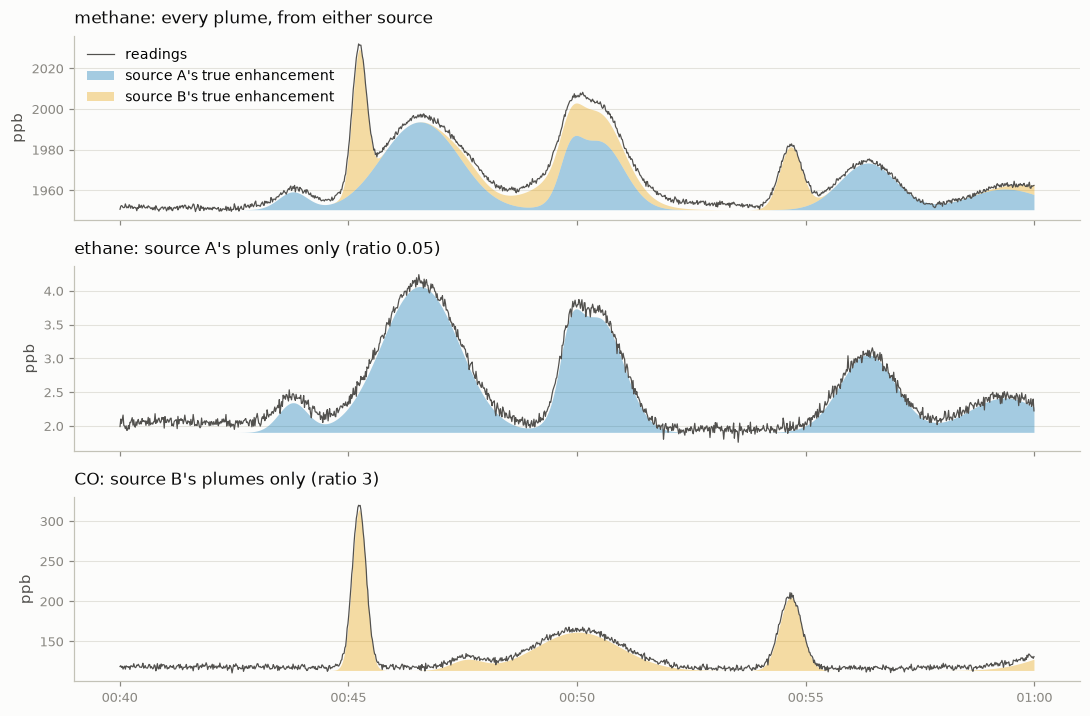

  ✔ §1 van.c2h6: one fit per member, keyed by the member's lowest-entry event   [972 members]
  ✔ §1 van.co: one fit per member, keyed by the member's lowest-entry event   [972 members]


In [2]:
start_section("§1")
# --- parameters --------------------------------------------------------------
SEED = 1  # which manufactured air
HOURS = 3.0  # how long it runs
SHOW = ("00:40", "01:00")  # the stretch drawn, hh:mm from the start

run = stage(seed=SEED, hours=HOURS)
fits = run["fits"]
# The events stage finds events in every gas; the ratios are fitted over the reference's.
catalog = run["catalog"][(run["catalog"].instrument == "van") & (run["catalog"].species == "ch4")]
config = ratios_config()
print("The configuration's ratios section, as YAML would hold it:\n")
print(yaml.safe_dump({"ratios": config.model_dump(mode="json")}, sort_keys=False))
members = fits[fits.numerator == "van.c2h6"]
print(
    f"{catalog.candidate_id.nunique()} candidates of van.ch4 over the three windows; "
    f"{len(members)} members; {len(fits)} fits ({fits.numerator.nunique()} numerators × York)"
)
print(fits.groupby(["numerator", "status"]).size().rename("fits").to_string())

stream, source = run["stream"], run["source"]
window = slice(START + pd.Timedelta(SHOW[0] + ":00"), START + pd.Timedelta(SHOW[1] + ":00"))
shown = stream.sel(time=window)
times = shown.time.values
inside = (stream.time.values >= times[0]) & (stream.time.values <= times[-1])
fig, axes = plt.subplots(3, 1, figsize=(10, 6.6), sharex=True)
for ax, gas, label in zip(axes, ("ch4", "c2h6", "co"), ("methane", "ethane", "CO")):
    ax.plot(times, shown[gas], color=INK2, lw=0.8, label="readings")
    floor = float(np.percentile(shown[gas], 2))
    below = np.zeros(int(inside.sum()))  # each source's methane stacked on the last's
    for name, color in (("A", C1), ("B", C2)):
        scale = 1.0 if gas == "ch4" else RATIOS[gas][name]
        if scale:
            part = scale * source[name][inside]
            ax.fill_between(
                times,
                floor + below,
                floor + below + part,
                color=color,
                alpha=0.35,
                lw=0,
                label=f"source {name}'s true enhancement",
            )
            below = below + part
    finish(ax, title=f"{label}", ylab="ppb", legend=gas == "ch4", loc="upper left")
clock(axes[-1])
axes[0].set_title("methane: every plume, from either source", pad=8)
axes[1].set_title("ethane: source A's plumes only (ratio 0.05)", pad=8)
axes[2].set_title("CO: source B's plumes only (ratio 3)", pad=8)
plt.tight_layout()
plt.show()

# The members by a plain loop over the catalog: each candidate's distinct
# (quantile, exit) intervals of the reference, keyed by the lowest entry's event.
expected = {}
for row in catalog.itertuples():
    key = (row.candidate_id, row.baseline_quantile, row.exit_multiple)
    if key not in expected or row.enter_multiple < expected[key][0]:
        expected[key] = (row.enter_multiple, row.event_id)
for numerator, rows in fits.groupby("numerator"):
    got = {
        (r.candidate_id, r.baseline_quantile, r.exit_multiple): r.event_id
        for r in rows.itertuples()
    }
    check(
        f"§1 {numerator}: one fit per member, keyed by the member's lowest-entry event",
        got == {k: v[1] for k, v in expected.items()},
        f"{len(got)} members",
    )

Each candidate is fitted for both numerators, so its two rows describe the
same stretches of air. Fits whose status is not `OK` hold no line (too few
pair cells, say); they stay in the table and pass no gate.

**Try it.** `SHOW = ("02:00", "02:20")` draws another stretch. `HOURS = 1.0`
makes about a third as many candidates; every section that follows works on
fewer.

---
## §2 One candidate's ratio

A candidate is seen by up to nine **members**, its (quantile, exit) intervals at
one baseline window, each fitted once. Its ratio is read from the members that
**pass the gates** (§3). They are **not repeat measurements**: the exits nest
and the quantiles move the baseline only a little, so the members share most of
their readings. Averaging them averages away no noise, and their number says
nothing about precision. That rules out an inverse-variance mean, which would
also favour the widest member, the one likeliest to hold a neighbour
(`METHODS.md` §5.5). Instead:

* **The ratio is the median member's slope.** The passing members' slopes,
  sorted, $b_{(1)} \le \dots \le b_{(n)}$; the ratio is the middle one, of two
  middle ones the lower:

  $$b = b_{(k)}, \qquad k = \left\lfloor \tfrac{n-1}{2} \right\rfloor + 1 .$$

  So the ratio, its σ, its n and its MSWD all describe one real fit.
* **σ_fit** is that member's widened σ, which holds the readings' noise, their
  persistence and the baseline's error (`METHODS.md` §5.4; notebook 09 §5–§6).
* **σ_method** is the spread the sweep's choices leave in the ratio: the
  standard deviation of the passing members' slopes,

  $$\sigma_\text{method} = \sqrt{\frac{1}{n-1}\sum_{k=1}^{n}\left(b_k - \bar b\right)^2},$$

  blank with one member. The window is not pooled into it: a ratio belongs to
  its own window, and the other windows' ratios are reported beside it.
* **σ_sys** is the ratio's share of the two gases' calibration errors. A gain
  error $g$ on a gas scales its enhancement by $1 + g$, so the slope moves by
  $b\,(1 + g_y)/(1 + g_x) \approx b\,(1 + g_y - g_x)$; with each gas's declared
  relative systematic term $s$,

  $$\sigma_\text{sys} = |b| \sqrt{s_x^2 + s_y^2}.$$

  An offset cancels in every enhancement and slope, so only the relative term
  counts (§5).
* **The combination** adds the terms that are known in quadrature, and the
  interval is the normal one:

  $$\sigma_\text{combined} = \sqrt{\sigma_\text{fit}^2 + \sigma_\text{method}^2 + \sigma_\text{sys}^2},
  \qquad b \pm z\,\sigma_\text{combined}, \quad z = \Phi^{-1}\!\left(\tfrac{1}{2} + \tfrac{\text{level}}{2}\right)$$

  ($z$ = 1.96 at 95 %). Quadrature treats the fit's error and the members'
  spread as independent, though members share readings; §4 tests whether the
  interval holds anyway.

 baseline_quantile  exit_multiple   n   slope  slope_sigma_widened  mswd  mswd_expected  signal  passes
              0.01              1 178 0.04984             0.003981  1.17           1.17   3.808    True
              0.01            1.5 173 0.05013              0.00413 1.193          1.167   3.747    True
              0.01              2 146 0.04814             0.004622 1.223          1.142   3.224    True
              0.05              1 176 0.05006             0.004695 1.189          1.234   3.753    True
              0.05            1.5 146  0.0485              0.00528 1.232          1.201   3.186    True
              0.05              2 140 0.04962              0.00541 1.258          1.202   3.032    True
               0.1              1 178 0.04929             0.005062   1.1          1.274   3.847    True
               0.1            1.5 173 0.04945             0.005196 1.123          1.267   3.801    True
               0.1              2 146 0.04808             0.0055

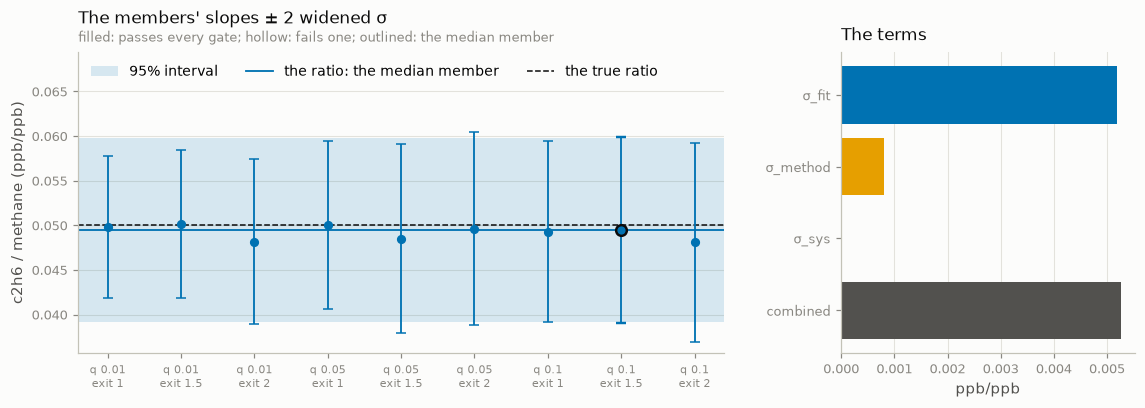

  ✔ §2 van.ch4/w600s/c35: the passing members are those the gates' rules pass   [9 of 9]
  ✔ §2 van.ch4/w600s/c35: the ratio and every term are §5.5's, worked out by hand   [median member van.ch4/w600s/q0.1/e3/x1.5/28]


In [3]:
start_section("§2")
# --- parameters --------------------------------------------------------------
SEED = 1  # which manufactured air (§1's)
CANDIDATE = "van.ch4/w600s/c35"  # which candidate: its window is in its name (w600s: 10 min)
NUMERATOR = "van.c2h6"  # 'van.c2h6' or 'van.co'
MIN_PEAK_Z = 5.0  # the height gate: the candidate's tallest member's peak z
LEVEL = 0.95  # the interval's confidence level

run = stage(seed=SEED)
config = ratios_config(min_peak_z=(MIN_PEAK_Z,))
table = candidate_ratios(run["fits"], run["candidates"], config.gates, confidence_level=LEVEL)
row = table[(table.candidate_id == CANDIDATE) & (table.numerator == NUMERATOR)].iloc[0]
members = run["fits"][
    (run["fits"].candidate_id == CANDIDATE) & (run["fits"].numerator == NUMERATOR)
]
members = members.sort_values(["baseline_quantile", "exit_multiple"]).reset_index(drop=True)
setting = {g: row[g] for g in GATE_NAMES}
members["passes"] = [reference_passes(fit, setting) for fit in members.to_dict("records")]
print(
    members[
        [
            "baseline_quantile",
            "exit_multiple",
            "n",
            "slope",
            "slope_sigma_widened",
            "mswd",
            "mswd_expected",
            "signal",
            "passes",
        ]
    ].to_string(index=False, float_format=lambda v: f"{v:.4g}")
)
gas = NUMERATOR.split(".")[1]
share = float(np.median(members.share_a[members.passes])) if members.passes.any() else np.nan
true_ratio = RATIOS[gas]["A" if share >= 0.5 else "B"] if np.isfinite(share) else np.nan
print(
    f"\n{CANDIDATE}, {NUMERATOR}: ratio {row.ratio:.5g}, from {row.n_members} passing members "
    f"(source A's share of its methane: {share:.3f}; true ratio {true_ratio:g})"
)
for term in ("sigma_fit", "sigma_method", "sigma_sys", "sigma_combined"):
    print(f"  {term:15s} {row[term]:.4g}")
print(f"  {LEVEL:.0%} interval   {row.lower:.5g} to {row.upper:.5g}")

fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.8), gridspec_kw={"width_ratios": [2.2, 1]})
ax = axes[0]
labels = [f"q {q:g}\nexit {x:g}" for q, x in zip(members.baseline_quantile, members.exit_multiple)]
positions = np.arange(len(members))
if row.n_members:
    ax.axhspan(row.lower, row.upper, color=C1, alpha=0.15, lw=0, label=f"{LEVEL:.0%} interval")
    ax.axhline(row.ratio, color=C1, lw=1.2, label="the ratio: the median member")
ax.axhline(true_ratio, color=INK, ls="--", lw=1, label="the true ratio")
for k, fit in members.iterrows():
    picked = fit.event_id == row.event_id
    color = C1 if fit.passes else MUTED
    ax.errorbar(
        k,
        fit.slope,
        yerr=2 * fit.slope_sigma_widened,
        fmt="o",
        ms=7 if picked else 5,
        color=color,
        mfc=color if fit.passes else "none",
        mec=INK if picked else color,
        mew=1.6 if picked else 1,
        capsize=3,
        lw=1.2,
    )
ax.set_xticks(positions, labels, fontsize=7.5)
finish(
    ax,
    title="The members' slopes ± 2 widened σ",
    sub="filled: passes every gate; hollow: fails one; outlined: the median member",
    ylab=f"{gas} / methane (ppb/ppb)",
)
# Room above the bars for the legend, in one row, whatever the members' spread.
low, high = ax.get_ylim()
ax.set_ylim(low, high + 0.3 * (high - low))
ax.legend(loc="upper left", ncol=3)
ax = axes[1]
terms = ["sigma_fit", "sigma_method", "sigma_sys", "sigma_combined"]
values = [row[t] if np.isfinite(row[t]) else 0.0 for t in terms]
ax.barh(range(4), values, color=[C1, C2, C3, INK2])
ax.set_yticks(range(4), ["σ_fit", "σ_method", "σ_sys", "combined"])
ax.invert_yaxis()
finish(ax, title="The terms", xlab="ppb/ppb", grid_axis="x")
plt.tight_layout()
plt.show()

passing = members[members.passes].to_dict("records")
check(
    f"§2 {CANDIDATE}: the passing members are those the gates' rules pass",
    row.n_members == len(passing),
    f"{row.n_members} of {len(members)}",
)
if passing:
    hand = reference_ratio(passing, LEVEL)
    same = all(
        math.isclose(row[k], v, rel_tol=1e-12, abs_tol=0)
        if np.isfinite(v)
        else not np.isfinite(row[k])
        for k, v in hand.items()
        if k != "event_id"
    )
    check(
        f"§2 {CANDIDATE}: the ratio and every term are §5.5's, worked out by hand",
        same and row.event_id == hand["event_id"],
        f"median member {hand['event_id']}",
    )

**Read it.** All nine members pass. Their slopes differ by about a sixth of
the median member's σ (σ_method 0.0008 against σ_fit 0.0052), so σ_method adds
almost nothing to the interval: 0.0494 ± 0.0053, its 95 % interval 0.0391 to
0.0598 holding the truth, 0.05. σ_sys is 0 because this air declares no calibration
error (§5 declares one).

**Try it.**

* `NUMERATOR = "van.co"`: the same candidate's CO against methane, an **upper
  limit**. Source A emits no CO, and the ratio is −0.10 ± 0.14, its 95 %
  interval −0.37 to 0.16 holding 0: a result, not a failure to find CO.
* `MIN_PEAK_Z = 20.0`: the candidate's tallest member is below 20 clean spreads,
  so no member passes and the row stays, its ratio blank and `n_members` 0, so
  that counting what a gate keeps needs no second table.
* `CANDIDATE = "van.ch4/w120s/c53"`: a candidate at the 2 min window whose plume
  is too wide for it. Of its nine members only the shortest (87 s of the
  120 s window) fits within 3/4 of it; the others (91–201 s) are left out by
  the crowding gate, and the ratio rests on that one member, its σ_method
  blank. Such a plume is read at a longer window, where it fits.

---
## §3 The gates, swept

A gate never changes a fit; it decides whether the fit counts (`METHODS.md`
§5.3). Every fit stores the numbers a gate reads, so a gate is a threshold
applied afterwards, and each takes a **list** of thresholds. Every combination
is one **gate setting**, and the ratio table holds every candidate at every
setting:

$$\text{rows} = \text{candidates} \times \text{numerators} \times \text{estimators}
\times \text{pair clocks} \times \prod_{\text{gates}} \left|\text{thresholds}\right| ,$$

read from one set of fits, with no refitting. So how many candidates count,
and how their ratios move, is seen across the gates as across windows. A
stricter gate only drops members, so it is not pooled into σ_method: its
effect is read across settings, beside each other.

Below, the height gate (the candidate's tallest member's peak z, in clean
spreads) and the one-source gate (the MSWD over what one source is expected to
read, against a χ² quantile) are each swept over three thresholds.

One gate is held at its default throughout: the **crowding gate**
(`max_window_fill`, 3/4). A plume that fills most of its baseline window lifts
the window's low quantile with its own readings, so the baseline eats part of
it and its ratio reads low; such a plume is read at a longer window, where it
fits (`METHODS.md` §5.3). The end of the cell counts what it holds back.

van.c2h6: candidates with a ratio at each setting, by what they truly are

kind                         mixture  mostly one  one source  with a ratio
min_peak_z mswd_probability                                               
3.0        0.950                   4          12          20            36
           0.990                   6          12          20            38
           0.999                  10          13          20            43
5.0        0.950                   3          12          18            33
           0.990                   5          12          18            35
           0.999                   9          13          18            40
8.0        0.950                   1           8          12            21
           0.990                   3           8          12            23
           0.999                   7           9          12            28


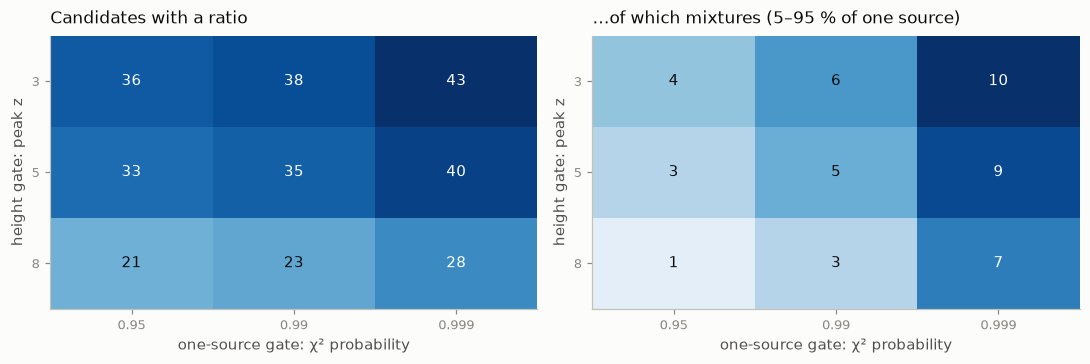

  ✔ §3 one row per candidate, numerator and gate setting, from one set of fits   [268 × 9]
  ✔ §3 a row no member passes keeps its place, its ratio blank   [1787 blank rows]


  ✔ §3 at every setting, the candidates with a ratio are those with a member the rules pass   [297 of 1206 rows]

The crowding gate, at the default height and one-source gates:


  on at 0.75 35 candidates with a ratio, 18 of them one source


  off      48 candidates with a ratio, 22 of them one source


In [4]:
start_section("§3")
# --- parameters --------------------------------------------------------------
SEED = 1  # which manufactured air (§1's)
HEIGHTS = (3.0, 5.0, 8.0)  # the height gate's thresholds, peak z
ONE_SOURCE = (0.95, 0.99, 0.999)  # the one-source gate's chi-squared probabilities (1: off)
NUMERATOR = "van.c2h6"  # which numerator to count
CROWDING = 0.75  # the crowding gate: the most of its window a member may fill (inf: off)

run = stage(seed=SEED)
config = ratios_config(min_peak_z=HEIGHTS, mswd_probability=ONE_SOURCE, max_window_fill=(CROWDING,))
table = candidate_ratios(run["fits"], run["candidates"], config.gates)
mine = truth_of(table[table.numerator == NUMERATOR], run["fits"])
kept = mine[mine.n_members > 0]
kind = np.where(
    kept.one_source,
    "one source",
    np.where((kept.share_a > 0.05) & (kept.share_a < 0.95), "mixture", "mostly one"),
)
counts = (
    kept.assign(kind=kind)
    .groupby(["min_peak_z", "mswd_probability", "kind"])
    .size()
    .unstack("kind", fill_value=0)
)
counts["with a ratio"] = counts.sum(axis=1)
print(f"{NUMERATOR}: candidates with a ratio at each setting, by what they truly are\n")
print(counts.to_string())

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for ax, (column, title) in zip(
    axes,
    (
        ("with a ratio", "Candidates with a ratio"),
        ("mixture", "…of which mixtures (5–95 % of one source)"),
    ),
):
    grid = (
        counts[column]
        .unstack("mswd_probability")
        .reindex(index=HEIGHTS, columns=ONE_SOURCE)
        .fillna(0)
    )
    ax.imshow(grid.to_numpy(), cmap="Blues", aspect="auto", vmin=0)
    darkest = max(float(grid.to_numpy().max()), 1.0)
    for (i, j), value in np.ndenumerate(grid.to_numpy()):
        ax.text(
            j,
            i,
            f"{int(value)}",
            ha="center",
            va="center",
            fontsize=10,
            color="white" if value > 0.6 * darkest else INK,
        )
    ax.set_xticks(range(len(ONE_SOURCE)), [f"{p:g}" for p in ONE_SOURCE])
    ax.set_yticks(range(len(HEIGHTS)), [f"{h:g}" for h in HEIGHTS])
    finish(
        ax,
        title=title,
        xlab="one-source gate: χ² probability",
        ylab="height gate: peak z",
        grid_axis=None,
    )
plt.tight_layout()
plt.show()

keys = run["fits"][["candidate_id", "numerator"]].drop_duplicates()
n_settings = len(HEIGHTS) * len(ONE_SOURCE)
check(
    "§3 one row per candidate, numerator and gate setting, from one set of fits",
    len(table) == len(keys) * n_settings,
    f"{len(keys)} × {n_settings}",
)
check(
    "§3 a row no member passes keeps its place, its ratio blank",
    bool((table.n_members == 0).eq(table.ratio.isna()).all()),
    f"{int((table.n_members == 0).sum())} blank rows",
)
by_hand = 0
for (h, p), rows in mine.groupby(["min_peak_z", "mswd_probability"]):
    setting = {g: rows[g].iloc[0] for g in GATE_NAMES}
    for candidate in rows.candidate_id:
        fits_of = run["fits"][
            (run["fits"].candidate_id == candidate) & (run["fits"].numerator == NUMERATOR)
        ]
        by_hand += any(reference_passes(fit, setting) for fit in fits_of.to_dict("records"))
check(
    "§3 at every setting, the candidates with a ratio are those with a member the rules pass",
    by_hand == len(kept),
    f"{by_hand} of {len(mine)} rows",
)

# The crowding gate, at the default height and one-source gates: on, and off.
print("\nThe crowding gate, at the default height and one-source gates:")
for label, most in ((f"on at {CROWDING:g}", CROWDING), ("off", float("inf"))):
    gated = truth_of(
        candidate_ratios(
            run["fits"], run["candidates"], ratios_config(max_window_fill=(most,)).gates
        ).query("numerator == @NUMERATOR"),
        run["fits"],
    )
    gated = gated[gated.n_members > 0]
    singles = int(gated.one_source.sum())
    print(f"  {label:8s} {len(gated)} candidates with a ratio, {singles} of them one source")

**Read it.** A higher peak z, or a lower χ² probability, keeps fewer
candidates. The one-source gate is the one that removes mixtures, since a
mixture's points scatter about any single line more than their noise allows:
loosening it from 0.95 to 0.999 lets in more than twice as many, while every
one-source candidate passes all three. The height gate removes small
candidates whatever they are. Neither empties the mixtures entirely: some
mixtures are dominated enough by one source to look like it (§5.3's measured
trade). Which setting to read is the reader's choice, made by looking across
them, as across windows.

The crowding gate holds back 13 of the 48 candidates that would otherwise have
a ratio at the default gates. Four of them are one source; the other nine are
mixtures or mostly one, since a plume too wide for its window often holds more
than one plume at that scale. A plume held back here is read at a longer
window.

**Try it.**

* `ONE_SOURCE = (0.9, 0.99, 1.0)`: at 1 the one-source gate is off, and the
  mixtures it was removing come back (44 instead of 3 to 6 at height 3).
* `NUMERATOR = "van.co"`: CO's fits have their own MSWDs, so the one-source
  gate keeps a different set of candidates for CO than for ethane (40 at the
  default gates against 35), though the candidates (and the height gate) are
  the same.
* `CROWDING = 0.5`: a stricter crowding gate. At the default height and
  one-source gates 26 candidates have a ratio (13 of them one source), against
  35 (18) at 3/4 and 48 (22) with the gate off.

---
## §4 Does the interval hold?

A 95 % interval is a promise: of many candidates, about 95 % of the intervals
hold the true ratio. The decisive check is to make many candidates whose
truth is known and count (`METHODS.md` §5.5). The test suite does it on six
six-hour records (`tests/ratios/test_ratio_coverage.py`, opt-in); this section
does it on a smaller set you can change.

The candidates scored are those whose passing members are each at least
99.9 % one source, so that one true ratio applies; mixtures have no true ratio
to hold. For each,

$$z = \frac{b - b_\text{true}}{\sigma_\text{combined}},$$

and a kept promise puts $|z| \le 1.96$ in 95 % of candidates, $z$ spread like
a standard normal. Both numerators are scored, with σ_fit alone beside the
combined σ.

numerator           σ  candidates  covered (|z| ≤ 1.96)  robust spread of z  median z
 van.c2h6    combined          49                 1.000               0.814    -0.150
 van.c2h6 σ_fit alone          49                 1.000               0.853    -0.150
   van.co    combined          48                 0.979               0.963    -0.241
   van.co σ_fit alone          48                 0.958               1.055    -0.249


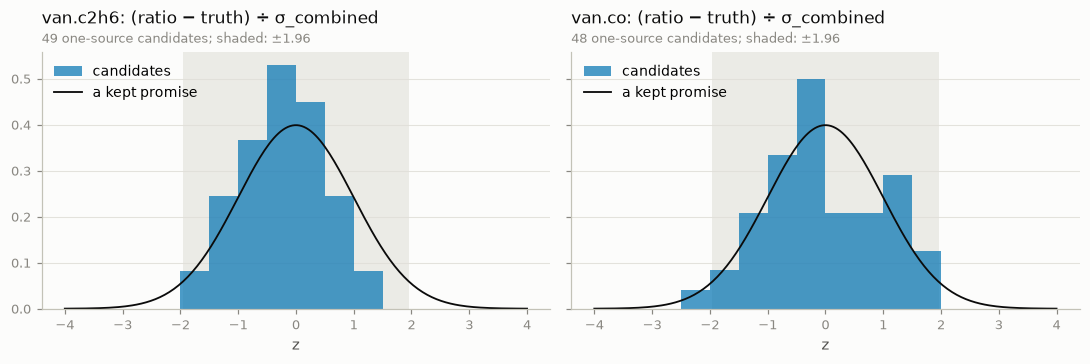

  ✔ §4 van.c2h6: the combined interval holds the truth no less often than it promises   [49 of 49 covered; P(≤ 49 | 95 %) = 1.00]
  ✔ §4 van.co: the combined interval holds the truth no less often than it promises   [47 of 48 covered; P(≤ 47 | 95 %) = 0.91]


In [5]:
start_section("§4")
# --- parameters --------------------------------------------------------------
SEEDS = (1, 2, 3)  # which manufactured airs (each about 40 s the first time)
HOURS = 3.0  # how long each runs
WALK = (30.0, 0.6, 20.0)  # how far each background wanders a day: methane, ethane, CO (ppb)
PLUMES_PER_HOUR = 20  # each source's plumes an hour

scored = []
for seed in SEEDS:
    run = stage(seed=seed, hours=HOURS, walk=WALK, plumes_per_hour=PLUMES_PER_HOUR)
    table = candidate_ratios(run["fits"], run["candidates"], ratios_config().gates)
    truth = truth_of(table[table.n_members > 0], run["fits"])
    scored.append(truth[truth.one_source].assign(seed=seed))
scored = pd.concat(scored, ignore_index=True)


def robust_spread(z):
    """1.4826 × the median absolute deviation: a standard deviation that ignores outliers."""
    return 1.4826 * float(np.median(np.abs(z - np.median(z))))


rows = []
for numerator, part in scored.groupby("numerator"):
    for label, sigma in (("combined", part.sigma_combined), ("σ_fit alone", part.sigma_fit)):
        z = (part.ratio - part.true_ratio) / sigma
        rows.append(
            {
                "numerator": numerator,
                "σ": label,
                "candidates": len(part),
                "covered (|z| ≤ 1.96)": float(np.mean(np.abs(z) <= 1.96)),
                "robust spread of z": robust_spread(z),
                "median z": float(np.median(z)),
            }
        )
coverage = pd.DataFrame(rows)
print(coverage.to_string(index=False, float_format=lambda v: f"{v:.3f}"))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
bins = np.linspace(-4, 4, 17)
grid = np.linspace(-4, 4, 200)
for ax, (numerator, part) in zip(axes, scored.groupby("numerator")):
    z = np.clip((part.ratio - part.true_ratio) / part.sigma_combined, -4, 4)
    ax.axvspan(-1.96, 1.96, color=GRID, alpha=0.6, lw=0)
    ax.hist(z, bins=bins, density=True, color=C1, alpha=0.7, label="candidates")
    ax.plot(
        grid,
        np.exp(-0.5 * grid**2) / math.sqrt(2 * math.pi),
        color=INK,
        lw=1.2,
        label="a kept promise",
    )
    finish(
        ax,
        title=f"{numerator}: (ratio − truth) ÷ σ_combined",
        sub=f"{len(part)} one-source candidates; shaded: ±1.96",
        xlab="z",
        legend=True,
        loc="upper left",
    )
plt.tight_layout()
plt.show()

for numerator, part in scored.groupby("numerator"):
    k = int(np.sum(np.abs(part.ratio - part.true_ratio) <= 1.96 * part.sigma_combined))
    tail = float(binom.cdf(k, len(part), 0.95))
    check(
        f"§4 {numerator}: the combined interval holds the truth no less often than it promises",
        tail > 0.01,
        f"{k} of {len(part)} covered; P(≤ {k} | 95 %) = {tail:.2f}",
    )

**Read it.** The intervals hold: all 49 ethane candidates and 47 of 48 CO
candidates, and on this air **err on the safe side**, z spreading 0.81
(ethane) and 0.96 (CO) of a standard normal. What makes them generous is the
baseline allowance (`METHODS.md` §5.4), measured on the readings outside every
event, which on air this crowded with plumes also holds plume tails and plumes
too small to be events and reads them as background wander. On real air with
known plumes added it errs wide where the air is quiet and a little narrow
where it is busy (§5.4, "On real air"). Fewer candidates are scored than
before the crowding gate (49 against 64): a candidate whose passing members
were all crowded now has none at its window. σ_fit alone covers nearly as
well: σ_method is about a quarter of σ_fit here.

**Try it.**

* `WALK = (0.0, 0.0, 0.0)`: flat backgrounds. What the allowance measures as
  wander is now all plume tails, and the intervals are wider still: z spreads
  0.68 and 0.63.
* `SEEDS = (4, 5, 6)`: other air. The intervals hold (ethane in 53 of 54
  candidates, CO in 50 of 54, within what 54 can tell from 95 %), and z
  spreads 1.10 and 1.21, a little wider than a standard normal: how generous
  the allowance is depends on the air.
* `PLUMES_PER_HOUR = 8`: fewer plumes overlap, so more candidates are one
  source (81 and 80). The intervals hold (95 % and 99 %), and z spreads 0.73
  and 0.94: fewer plumes alone do not make them tighter.

---
## §5 The systematic: the one term that never averages down

An analyzer calibrated a few percent off reads every enhancement a few percent
off, in every plume alike. Each candidate's ratio moves by the same factor, and
nothing inside the data can see it: the members agree with each other, the
MSWD is untouched, and averaging many candidates only pins down the wrong
value more tightly. The only defence is to **state** the calibration's
uncertainty, as a relative systematic term in the manifest (`METHODS.md` §2.2),
and carry it as σ_sys. TSARA never estimates it and never corrects for it.

Here the ethane readings carry a gain: they read `GAIN` times the air. The
manifest's statement about it is `SYSTEMATIC`: `declared` (a relative term
`DECLARED`), `zero` (no systematic error), or `unknown` (not stated). Source
A's candidates are drawn with two intervals each: the random terms alone,
σ_fit and σ_method, and the combined one with σ_sys added.

10 candidates of source A alone (all windows); true ratio 0.05, read 1.1 times: 0.055
  the truth inside the random interval in 80%, inside the combined one in 100%
  their mean ratio 0.0551 ± 0.0017 from the random terms (as if independent): 3.0 of those from the truth
  σ_sys at that ratio: 0.0055


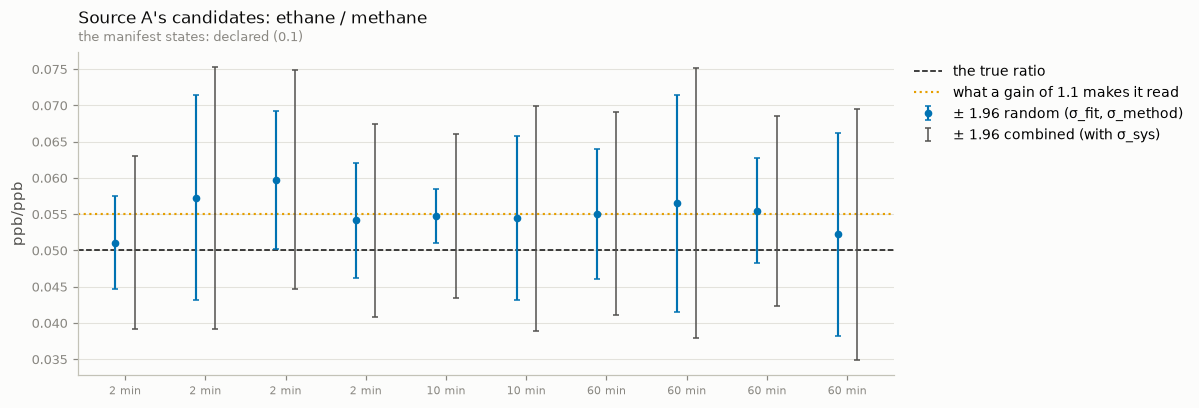

  ✔ §5 σ_sys is |b| sqrt(s_x^2 + s_y^2) from what the manifest states (declared)
  ✔ §5 the combined σ is the known terms in quadrature


In [6]:
start_section("§5")
# --- parameters --------------------------------------------------------------
SEED = 1  # which manufactured air (§1's plumes and noise, with the gain added)
GAIN = 1.10  # what the ethane readings read, as a multiple of the air (1: calibrated)
SYSTEMATIC = "declared"  # the manifest's statement: 'declared', 'zero' or 'unknown'
DECLARED = 0.10  # with 'declared', the relative systematic term stated for ethane

run = stage(seed=SEED, gain=GAIN, systematic=SYSTEMATIC, declared=DECLARED)
table = candidate_ratios(run["fits"], run["candidates"], ratios_config().gates)
ethane = truth_of(table[(table.numerator == "van.c2h6") & (table.n_members > 0)], run["fits"])
a = ethane[ethane.one_source & (ethane.share_a >= 0.5)].sort_values(
    ["baseline_window", "peak_time"]
)
a = a.reset_index(drop=True)
random_part = np.hypot(a.sigma_fit, np.nan_to_num(a.sigma_method))
z = 1.96
held_random = np.abs(a.ratio - RATIOS["c2h6"]["A"]) <= z * random_part
held_combined = np.abs(a.ratio - RATIOS["c2h6"]["A"]) <= z * a.sigma_combined
mean = float(a.ratio.mean())
error_random = float(np.sqrt(np.sum(random_part**2))) / len(a)
true_a = RATIOS["c2h6"]["A"]
print(
    f"{len(a)} candidates of source A alone (all windows); true ratio {true_a:g}, "
    f"read {GAIN:g} times: {GAIN * true_a:g}"
)
print(
    f"  the truth inside the random interval in {held_random.mean():.0%}, "
    f"inside the combined one in {held_combined.mean():.0%}"
)
print(
    f"  their mean ratio {mean:.4f} ± {error_random:.4f} from the random terms "
    f"(as if independent): {abs(mean - true_a) / error_random:.1f} of those from the truth"
)
sys_typical = float(np.nanmedian(a.sigma_sys)) if a.sigma_sys_known.all() else float("nan")
print(f"  σ_sys at that ratio: {sys_typical:.4f}")

fig, ax = plt.subplots(figsize=(11, 3.8))
x = np.arange(len(a))
ax.axhline(RATIOS["c2h6"]["A"], color=INK, ls="--", lw=1, label="the true ratio")
ax.axhline(
    GAIN * RATIOS["c2h6"]["A"],
    color=C2,
    ls=":",
    lw=1.4,
    label=f"what a gain of {GAIN:g} makes it read",
)
ax.errorbar(
    x - 0.12,
    a.ratio,
    yerr=z * random_part,
    fmt="o",
    ms=4,
    color=C1,
    capsize=2,
    label="± 1.96 random (σ_fit, σ_method)",
)
ax.errorbar(
    x + 0.12,
    a.ratio,
    yerr=z * a.sigma_combined,
    fmt="none",
    color=INK2,
    capsize=2,
    lw=1,
    label="± 1.96 combined (with σ_sys)",
)
ax.set_xticks(x, [f"{w / 60:g} min" for w in a.baseline_window], fontsize=7.5)
finish(
    ax,
    title="Source A's candidates: ethane / methane",
    sub=f"the manifest states: {SYSTEMATIC}"
    + (f" ({DECLARED:g})" if SYSTEMATIC == "declared" else ""),
    ylab="ppb/ppb",
)
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0))
plt.tight_layout()
plt.show()

rows = table[table.n_members > 0]
if SYSTEMATIC == "declared":
    expected = np.where(rows.numerator == "van.c2h6", np.abs(rows.ratio) * DECLARED, 0.0)
    rule = np.allclose(rows.sigma_sys, expected, rtol=1e-12, atol=0) and rows.sigma_sys_known.all()
elif SYSTEMATIC == "zero":
    rule = bool((rows.sigma_sys == 0).all() and rows.sigma_sys_known.all())
else:
    is_ethane = rows.numerator == "van.c2h6"
    rule = bool((~rows.sigma_sys_known[is_ethane]).all() and rows.sigma_sys[is_ethane].isna().all())
check(f"§5 σ_sys is |b| sqrt(s_x^2 + s_y^2) from what the manifest states ({SYSTEMATIC})", rule)
known = [
    np.where(np.isfinite(t), t, 0.0) ** 2
    for t in (rows.sigma_fit, rows.sigma_method, rows.sigma_sys)
]
check(
    "§5 the combined σ is the known terms in quadrature",
    np.allclose(rows.sigma_combined, np.sqrt(sum(known)), rtol=1e-12, atol=0),
)

**Read it.** A's ratios scatter about what the gain makes them read, not
about the truth. The random intervals hold the truth in 8 of the 10
candidates where they promise 95 %: they say how well each ratio is
measured, not how well the analyzer is calibrated. The mean of the candidates
is three of its own random standard errors from the truth, and more
candidates would make that worse, since the offset stays 10 % while the
standard error shrinks as $1/\sqrt{K}$. The combined intervals, with σ_sys,
hold the truth in every candidate, because the 10 % was stated.

**Try it.**

* `SYSTEMATIC = "unknown"`: the calibration is not stated. σ_sys is blank,
  `sigma_sys_known` is False on every ethane row, and the combined interval is
  the random one: it misses the truth as often.
* `DECLARED = 0.0`: the manifest says the ethane analyzer is perfectly
  calibrated, and it is not. σ_sys is 0, every check passes, and the intervals
  miss: TSARA carries what is declared and cannot tell it is wrong.
* `GAIN = 1.0`: calibrated, with the 10 % still declared. The intervals are
  wider than they need be, and they hold the truth.

---
## §6 The fingerprint: a candidate's ratios across gases

A candidate's ratio against every numerator, side by side, is its
**fingerprint** (`tsara.ratios.fingerprints`), a pivot of the ratio table at
one estimator, pair clock and gate setting, never stored. Two sources with
different emissions separate in it: here A at (0.05, 0) and B at (0, 3), in
ethane / methane against CO / methane.

**Upper limits are results.** The signal gate reads the reference alone, so a
candidate is fitted against every numerator whether that gas rose or not. A's
CO ratio sits near 0 with an interval, and that interval is the result, an
upper limit on A's CO: not a failure, and not the same as no measurement.

66 candidates at 2 min, 10 with a ratio for both gases; the first of those:

numerator          van.c2h6  van.co
candidate_id                       
van.ch4/w120s/c1    -0.0012  3.2507
van.ch4/w120s/c11   -0.0071  3.3490
van.ch4/w120s/c15   -0.0027  2.6487
van.ch4/w120s/c16    0.0461 -0.0438
van.ch4/w120s/c18    0.0523  0.0487
van.ch4/w120s/c21    0.0510 -0.1462



with both: 4 of source A alone, 1 of source B alone, 5 mixtures or mostly one


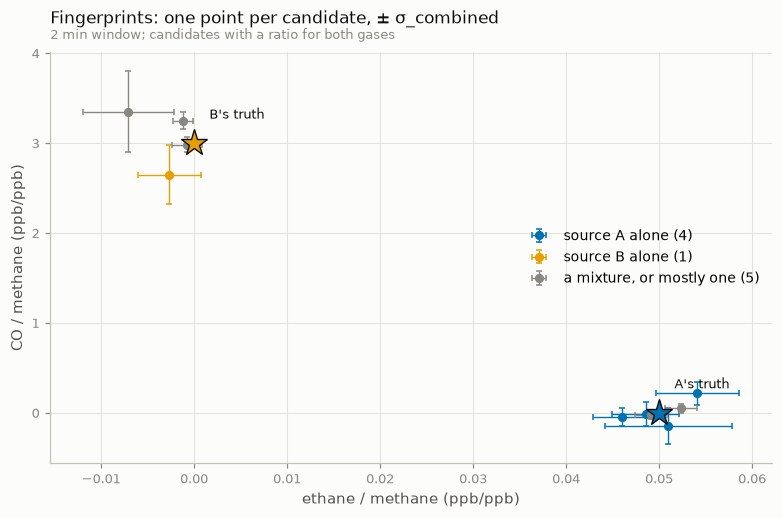

  ✔ §6 the fingerprint is the ratio table's rows, one candidate a line, one numerator a column   [66 × 2]


In [7]:
start_section("§6")
# --- parameters --------------------------------------------------------------
SEED = 1  # which manufactured air (§1's)
WINDOW = 120.0  # which baseline window's candidates (s): 120, 600 or 3600
MIN_PEAK_Z = 5.0  # the height gate

run = stage(seed=SEED)
config = ratios_config(min_peak_z=(MIN_PEAK_Z,))
table = candidate_ratios(run["fits"], run["candidates"], config.gates)
at = {"method": "york", "period": "native", "baseline_window": WINDOW}
ratio = fingerprints(table, **at)
sigma = fingerprints(table, value="sigma_combined", **at)
with_both = int(ratio.notna().all(axis=1).sum())
print(
    f"{len(ratio)} candidates at {WINDOW / 60:g} min, {with_both} with a ratio for both gases; "
    "the first of those:\n"
)
print(ratio[ratio.notna().all(axis=1)].head(6).to_string(float_format=lambda v: f"{v:.4f}"))

truth = truth_of(table[(table.baseline_window == WINDOW) & (table.n_members > 0)], run["fits"])
share = truth.groupby("candidate_id").share_a.median().reindex(ratio.index)
single = truth.groupby("candidate_id").one_source.all().reindex(ratio.index, fill_value=False)
both = ratio.notna().all(axis=1)
print(
    f"\nwith both: {int((both & single & (share >= 0.5)).sum())} of source A alone, "
    f"{int((both & single & (share < 0.5)).sum())} of source B alone, "
    f"{int((both & ~single).sum())} mixtures or mostly one"
)
fig, ax = plt.subplots(figsize=(7.2, 4.8))
for name, mask, color in (
    ("source A alone", single & (share >= 0.5), C1),
    ("source B alone", single & (share < 0.5), C2),
    ("a mixture, or mostly one", ~single, MUTED),
):
    shown = both & mask
    ax.errorbar(
        ratio.loc[shown, "van.c2h6"],
        ratio.loc[shown, "van.co"],
        xerr=sigma.loc[shown, "van.c2h6"],
        yerr=sigma.loc[shown, "van.co"],
        fmt="o",
        ms=5,
        color=color,
        capsize=2,
        lw=0.9,
        label=f"{name} ({int(shown.sum())})",
    )
for name, color in (("A", C1), ("B", C2)):
    ax.plot(
        RATIOS["c2h6"][name],
        RATIOS["co"][name],
        marker="*",
        ms=18,
        color=color,
        mec=INK,
        mew=0.9,
        ls="none",
        zorder=5,
    )
    ax.annotate(
        f"{name}'s truth",
        (RATIOS["c2h6"][name], RATIOS["co"][name]),
        xytext=(10, 16),
        textcoords="offset points",
        fontsize=8.5,
        color=INK,
        zorder=6,
    )
finish(
    ax,
    title="Fingerprints: one point per candidate, ± σ_combined",
    sub=f"{WINDOW / 60:g} min window; candidates with a ratio for both gases",
    xlab="ethane / methane (ppb/ppb)",
    ylab="CO / methane (ppb/ppb)",
    legend=True,
    loc="center right",
    grid_axis="both",
)
plt.tight_layout()
plt.show()

by_hand = {}
for row in table[(table.baseline_window == WINDOW)].itertuples():
    by_hand.setdefault(row.candidate_id, {})[row.numerator] = row.ratio
same = all(
    (np.isnan(by_hand[c][n]) and np.isnan(ratio.loc[c, n])) or by_hand[c][n] == ratio.loc[c, n]
    for c in ratio.index
    for n in ratio.columns
)
check(
    "§6 the fingerprint is the ratio table's rows, one candidate a line, one numerator a column",
    same and set(by_hand) == set(ratio.index),
    f"{len(ratio)} × {ratio.shape[1]}",
)

**Read it.** A's candidates gather near A's truth and B's near B's, each with
an interval on the gas it does not emit. The grey points between are
candidates that are not one source, mixtures the one-source gate let through
or a source dominating another: they fall between the two, as a mixture of the
two should. A blank in the table means no member passed the gates *for that
numerator* (CO's fits have their own MSWDs), not that the gas was absent.

**Try it.**

* `WINDOW = 600.0`: the 10 min window's candidates: 9 with a ratio for both
  gases (2 of A alone, 3 of B alone, 4 neither), against 10 at 2 min, where
  the crowding gate leaves the plumes too wide for that window to the longer
  ones.

---
## §7 The sweep summary: where the fits count and the budget closes

`tsara.ratios.sweep_summary` reads the fit table at every **sweep point**
(numerator, estimator, pair clock, window, quantile, exit) and every gate
setting, and returns an xarray Dataset of counts and summaries (`METHODS.md`
§5.6). It is a view built on demand, never saved: a saved one would freeze one
population and one set of gates.

Its most telling layer is the **Birge ratio** over a **population**, the
candidates a reader names as one source (the burps of one pipeline on parked
nights, say). With $K$ passing fits of slopes $b_k$ and widened σs $\sigma_k$,

$$R_B = \sqrt{\frac{1}{K-1}\sum_{k=1}^{K} \frac{\left(b_k - \bar b\right)^2}{\sigma_k^2}},
\qquad \bar b = \frac{\sum_k b_k / \sigma_k^2}{\sum_k 1/\sigma_k^2}$$

(`METHODS.md` §5.1). Near 1, the fits' σs explain the scatter across
candidates: the error budget closes. Well above 1, they do not, or the
population is not one source. Over every candidate at once it mixes sources
and reads high by construction, which is why the population is named.
Here the population is named from the truth, as a reader names it from what
they know of the place.

<xarray.Dataset> Size: 17kB
Dimensions:              (numerator: 2, estimator: 1, period: 1,
                          baseline_window: 3, baseline_quantile: 3,
                          exit_multiple: 3, min_peak_z: 3, min_points: 1,
                          min_signal: 1, mswd_probability: 1,
                          plateau_probability: 1, max_window_fill: 1)
Coordinates:
  * numerator            (numerator) object 16B 'van.c2h6' 'van.co'
  * estimator            (estimator) object 8B 'york'
  * period               (period) object 8B 'native'
  * baseline_window      (baseline_window) float64 24B 120.0 600.0 3.6e+03
  * baseline_quantile    (baseline_quantile) float64 24B 0.01 0.05 0.1
  * exit_multiple        (exit_multiple) float64 24B 1.0 1.5 2.0
  * min_peak_z           (min_peak_z) float64 24B 3.0 5.0 8.0
  * min_points           (min_points) int64 8B 8
  * min_signal           (min_signal) float64 8B 2.0
  * mswd_probability     (mswd_probability) float64 8B 0.99
  * platea

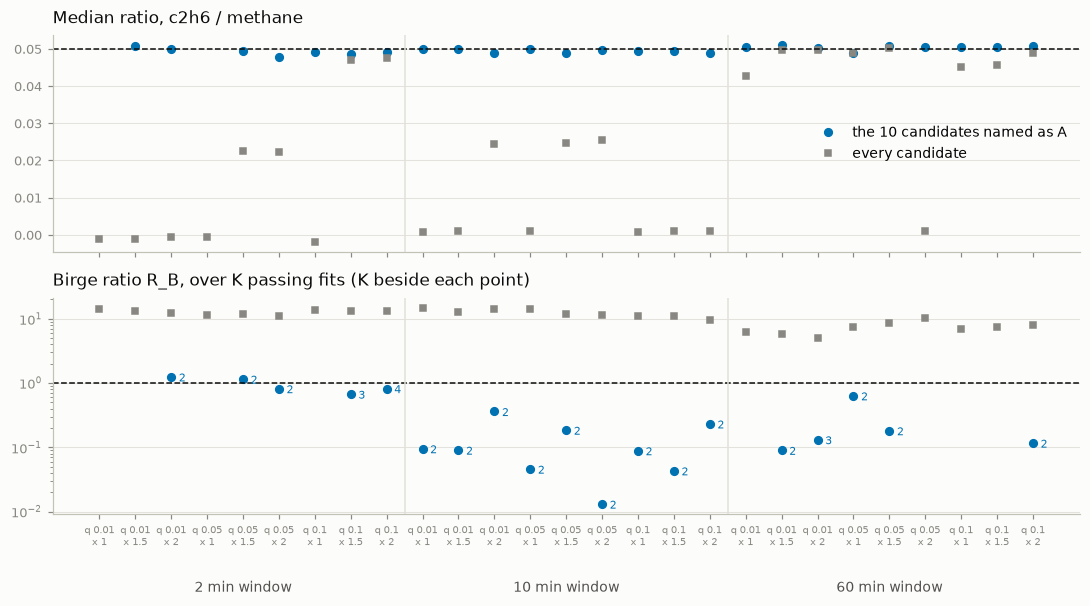

  ✔ §7 R_B at one sweep point is §5.1's, over the population's passing fits   [K = 4, R_B 0.818]
  ✔ §7 n_candidates is how many ratios candidate_ratios gives, at every window and setting   [18 cells]


In [8]:
start_section("§7")
# --- parameters --------------------------------------------------------------
SEED = 1  # which manufactured air (§1's)
POPULATION = "A"  # the candidates named as one source: 'A' or 'B'
HEIGHTS = (3.0, 5.0, 8.0)  # the height gate's thresholds, a dimension of the summary

run = stage(seed=SEED)
config = ratios_config(min_peak_z=HEIGHTS)
fits = run["fits"].drop(columns="share_a")
table = candidate_ratios(fits, run["candidates"], config.gates)
gas = "van.c2h6" if POPULATION == "A" else "van.co"  # each source read on the gas it emits
truth = truth_of(
    table[(table.n_members > 0) & (table.min_peak_z == 5.0) & (table.numerator == gas)], run["fits"]
)
of_one = truth[truth.one_source & ((truth.share_a >= 0.5) == (POPULATION == "A"))]
named = sorted(set(of_one.candidate_id))
summary = sweep_summary(fits, config.gates, population=named)
everyone = sweep_summary(fits, config.gates)
print(summary)

at = {"numerator": gas, "estimator": "york", "period": "native", "min_peak_z": 5.0}
fig, axes = plt.subplots(2, 1, figsize=(10, 5.6), sharex=True)
points = (
    summary.sel(at)
    .squeeze(drop=True)
    .stack(point=("baseline_window", "baseline_quantile", "exit_multiple"))
)
others = (
    everyone.sel(at)
    .squeeze(drop=True)
    .stack(point=("baseline_window", "baseline_quantile", "exit_multiple"))
)
x = np.arange(points.sizes["point"])
for ax, layer, title in (
    (axes[0], "median_ratio", f"Median ratio, {gas.split('.')[1]} / methane"),
    (axes[1], "birge_ratio", "Birge ratio R_B, over K passing fits (K beside each point)"),
):
    ax.plot(
        x,
        points[layer],
        "o",
        color=C1,
        ms=5,
        label=f"the {len(named)} candidates named as {POPULATION}",
    )
    ax.plot(x, others[layer], "s", color=MUTED, ms=4, label="every candidate")
    finish(ax, title=title, legend=layer == "median_ratio", loc="center right")
for k, (value, count) in enumerate(zip(points.birge_ratio.values, points.n_population.values)):
    if np.isfinite(value):
        axes[1].annotate(
            f"{int(count)}",
            (k, value),
            xytext=(5, -3),
            textcoords="offset points",
            fontsize=7,
            color=C1,
        )
axes[0].axhline(RATIOS[gas.split(".")[1]][POPULATION], color=INK, ls="--", lw=1)
axes[1].axhline(1.0, color=INK, ls="--", lw=1)
axes[1].set_yscale("log")
labels = [f"q {q:g}\nx {e:g}" for _, q, e in points.point.values]
axes[1].set_xticks(x, labels, fontsize=6.5)
for k, window in enumerate(np.unique(points.baseline_window)):
    axes[1].text(
        9 * k + 4,
        -0.36,
        f"{window / 60:g} min window",
        transform=axes[1].get_xaxis_transform(),
        ha="center",
        fontsize=9,
        color=INK2,
    )
    for ax in axes:
        if k:
            ax.axvline(9 * k - 0.5, color=GRID, lw=1)
plt.tight_layout()
plt.show()

# The sweep point whose population has the most passing fits, so that R_B has fits to read.
counts = summary.n_population.sel(at).squeeze(drop=True)
best = counts.where(counts == counts.max(), drop=True)
point = {
    **at,
    **{
        dim: float(best[dim].values[0])
        for dim in ("baseline_window", "baseline_quantile", "exit_multiple")
    },
}
setting = {
    "min_peak_z": 5.0,
    "min_points": 8,
    "min_signal": 2.0,
    "mswd_probability": 0.99,
    "plateau_probability": 1.0,
    "max_window_fill": 0.75,
}
mine = fits[
    (fits.numerator == gas)
    & (fits.baseline_window == point["baseline_window"])
    & (fits.baseline_quantile == point["baseline_quantile"])
    & (fits.exit_multiple == point["exit_multiple"])
    & fits.candidate_id.isin(named)
]
kept = [fit for fit in mine.to_dict("records") if reference_passes(fit, setting)]
got = float(summary.birge_ratio.sel(point).squeeze())
if len(kept) > 1:
    hand = reference_birge([f["slope"] for f in kept], [f["slope_sigma_widened"] for f in kept])
    check(
        "§7 R_B at one sweep point is §5.1's, over the population's passing fits",
        math.isclose(got, hand, rel_tol=1e-12),
        f"K = {len(kept)}, R_B {hand:.3f}",
    )
counted = table[table.n_members > 0].groupby(["numerator", "baseline_window", "min_peak_z"]).size()
# The other dimensions hold one value each here, so summing over them reads the cell.
n_candidates = summary.n_candidates.to_series().groupby(level=list(counted.index.names)).sum()
n_candidates = n_candidates[n_candidates > 0]
check(
    "§7 n_candidates is how many ratios candidate_ratios gives, at every window and setting",
    n_candidates.to_dict() == counted.to_dict(),
    f"{len(counted)} cells",
)

**Read it.** Over the named population the median ratio sits near the truth
at every sweep point. At the 2 min window, with two to four of its candidates
at each point (fewer than before the crowding gate, which leaves the plumes too
wide for that window to the longer ones), R_B is near 1, 0.7 to 1.3: the fits'
σs account for the scatter between them, a little generously, as §4 found. At
10 and 60 min only two or three named candidates pass at each point, and R_B
over two fits is a single z-value, so its 0.01–0.63 says little: the Birge
ratio needs a population. Over every candidate the median ratio is
pulled between the two sources and R_B is 5 to 15: a whole record mixes
sources, and R_B says so. A point with one fit has no R_B. On real data, `population` is the reader's
judgement, and R_B across the sweep is where to look for sweep points at which
the budget closes (`METHODS.md` §5.1).

**Try it.**

* `POPULATION = "B"`: the combustion source's candidates, read on CO.
* `HEIGHTS = (5.0,)`: one height. The summary keeps the dimension, with one
  value, so code that selects on it reads the same at any number of settings.

---
## §8 Saving and loading the stage's tables

`save_ratios` writes the stage's products under a bundle's `ratios/`
(`METHODS.md` §5.7): `fits.parquet`, `ratios.parquet` (every candidate's
ratio at every gate setting, each naming its candidate's parent at the nearest
longer window) and `analysis.yaml` (the `ratios:` section alone). The ratio
table is built from the fits, the events stage's candidate table and the
configuration's gates as it is written, so the three files cannot disagree.
What the configuration does not ask for is refused before anything is
written.

In [9]:
start_section("§8")
# --- parameters --------------------------------------------------------------
SEED = 1  # which manufactured air (§1's)
HEIGHTS = (3.0, 5.0)  # the height gate's thresholds the ratio table is written at

run = stage(seed=SEED)
config = ratios_config(min_peak_z=HEIGHTS)
fits = run["fits"].drop(
    columns="share_a"
)  # the stage's table, without this notebook's truth column
bundle = Path(tempfile.mkdtemp()) / "demo_bundle"
written = save_ratios(fits, bundle, candidates=run["candidates"], ratios=config)
for file in sorted(written.iterdir()):
    print(f"  {file.relative_to(bundle)}   {file.stat().st_size:,} bytes")
loaded = load_ratios(bundle)
print(
    f"\nloaded: {len(loaded.fits)} fits, {len(loaded.candidate_ratios)} ratio rows, gates "
    f"{loaded.ratios.gates.min_peak_z}"
)

for label, attempt in (
    (
        "with this notebook's truth column",
        lambda: save_ratios(run["fits"], bundle, candidates=run["candidates"], ratios=config),
    ),
    (
        "under a configuration with no CO",
        lambda: save_ratios(
            fits,
            bundle,
            candidates=run["candidates"],
            ratios=config.model_copy(
                update={"sets": (config.sets[0].model_copy(update={"numerators": ("van.c2h6",)}),)}
            ),
        ),
    ),
):
    try:
        attempt()
        print(f"\nsaved {label}: not refused")
    except TsaraBundleError as error:
        print(f"\nrefused, {label}:\n  {error}")

pd.testing.assert_frame_equal(loaded.fits, fits.reset_index(drop=True))
check("§8 the fits come back exactly, column types included", True, f"{len(fits)} rows")
fresh = candidate_ratios(fits, run["candidates"], config.gates)
check(
    "§8 the saved ratio table is the one the fits, candidates and gates make",
    loaded.candidate_ratios.equals(fresh),
    f"{len(fresh)} rows",
)
check("§8 the configuration comes back as written", loaded.ratios == config)
parents = run["candidates"].set_index("candidate_id").parent_candidate_id
named = loaded.candidate_ratios.candidate_id.map(parents)
check(
    "§8 each ratio row names its candidate's parent, as the events stage's table gives it",
    named.fillna("").equals(loaded.candidate_ratios.parent_candidate_id.fillna("")),
)

  ratios/analysis.yaml   327 bytes
  ratios/fits.parquet   311,777 bytes
  ratios/ratios.parquet   30,524 bytes

loaded: 1944 fits, 536 ratio rows, gates (3.0, 5.0)

refused, with this notebook's truth column:
  save_ratios was handed fits whose columns are not the fit table's; build them with ratio_fits. Columns: ['event_id', 'candidate_id', 'reference', 'numerator', 'period', 'method', 'baseline_window', 'baseline_quantile']...

refused, under a configuration with no CO:
  save_ratios was handed fits of 'van.co' against 'van.ch4', which that ratio set does not name; it names ['van.c2h6'].
  ✔ §8 the fits come back exactly, column types included   [1944 rows]


  ✔ §8 the saved ratio table is the one the fits, candidates and gates make   [536 rows]
  ✔ §8 the configuration comes back as written
  ✔ §8 each ratio row names its candidate's parent, as the events stage's table gives it


**Read it.** Both refusals leave the bundle as it was: the fit table must be
the stage's own columns, and the configuration beside it must ask for every
reference, numerator, estimator and pair clock the fits hold. A part of a
run's fits (one numerator, say) can be saved under the configuration that made
them. The sweep summary and the fingerprints are not saved: they are built
from these tables when wanted.

**Try it.** `HEIGHTS = (3.0, 5.0, 8.0)`: the ratio table grows by half, the
fits do not change.

---
## Scoreboard

Every check printed above, gathered: each line a claim about TSARA, compared
as it ran against a reference written independently in this notebook or the
truth the recipe manufactured.

In [10]:
held = sum(ok for ok, _ in CHECKS.values())
print(f"{held} of {len(CHECKS)} checks hold\n")
for claim, (ok, detail) in CHECKS.items():
    print(f"  {'✔' if ok else '✘'} {claim}" + (f"   [{detail}]" if detail else ""))

18 of 18 checks hold

  ✔ §1 van.c2h6: one fit per member, keyed by the member's lowest-entry event   [972 members]
  ✔ §1 van.co: one fit per member, keyed by the member's lowest-entry event   [972 members]
  ✔ §2 van.ch4/w600s/c35: the passing members are those the gates' rules pass   [9 of 9]
  ✔ §2 van.ch4/w600s/c35: the ratio and every term are §5.5's, worked out by hand   [median member van.ch4/w600s/q0.1/e3/x1.5/28]
  ✔ §3 one row per candidate, numerator and gate setting, from one set of fits   [268 × 9]
  ✔ §3 a row no member passes keeps its place, its ratio blank   [1787 blank rows]
  ✔ §3 at every setting, the candidates with a ratio are those with a member the rules pass   [297 of 1206 rows]
  ✔ §4 van.c2h6: the combined interval holds the truth no less often than it promises   [49 of 49 covered; P(≤ 49 | 95 %) = 1.00]
  ✔ §4 van.co: the combined interval holds the truth no less often than it promises   [47 of 48 covered; P(≤ 47 | 95 %) = 0.91]
  ✔ §5 σ_sys is |b| sqrt(s_x